# 1. Load Libraries & Setup                


In [1]:
import sys                                          
import os                                           
import pandas as pd                                 
import numpy as np                                  
import matplotlib.pyplot as plt                     
import seaborn as sns                               
                                                    
                                                    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler    
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier     
from sklearn.ensemble import RandomForestClassifier 
from xgboost import XGBClassifier                   
from sklearn.metrics import (                       
    classification_report,                          
    confusion_matrix,                               
    roc_auc_score,                                  
    roc_curve,                                      
    f1_score,                                       
    precision_score,                                
    recall_score                                    
)                                                   

# 2. Data Preparation

In [2]:
# Load processed dataset                                                   
df_wine = pd.read_csv(r"..\data\processed\wine_quality_combined.csv")      
                                                                           
                                                                           
# Create binary target and encode categorical feature                      
df_wine['quality_label'] = (df_wine['quality'] >= 7).astype(int)           
df_wine['type_code'] = (df_wine['type'] == 'white').astype(int)            
                                                                           
                                                                           
# Separate X and y                                                         
X = df_wine.drop(columns=['quality', 'quality_label', 'type'])             
y = df_wine['quality_label']                                               
                                                                           
                                                                           
# Train-Test Split (80% train, 20% test, stratified)                       
X_train, X_test, y_train, y_test = train_test_split(                       
    X, y, test_size=0.2, random_state=42, stratify=y                       
)                                                                          
                                                                           
                                                                           
# Scale features for models that require scaling (e.g. Logistic Regression)
scaler = StandardScaler()                                                  
X_train_scaled = scaler.fit_transform(X_train)                             
X_test_scaled = scaler.transform(X_test)                                   
                                                                           
                                                                           
# Calculate class ratio for XGBoost scale_pos_weight                       
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)            

# 3. Model Dictionary Setup

In [3]:
models = {                                                                                                
    "Logistic Regression": {                                                                              
        "model": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),             
        "scaled": True                                                                                    
    },                                                                                                    
    "Decision Tree": {                                                                                    
        "model": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),           
        "scaled": False                                                                                   
    },                                                                                                    
    "Random Forest": {                                                                                    
        "model": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),      
        "scaled": False                                                                                   
    },                                                                                                    
    "XGBoost": {                                                                                          
        "model": XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
        "scaled": False                                                                                   
    }                                                                                                     
}                                                                                                         

# 4. Training, Evaluation & Metrics Summary

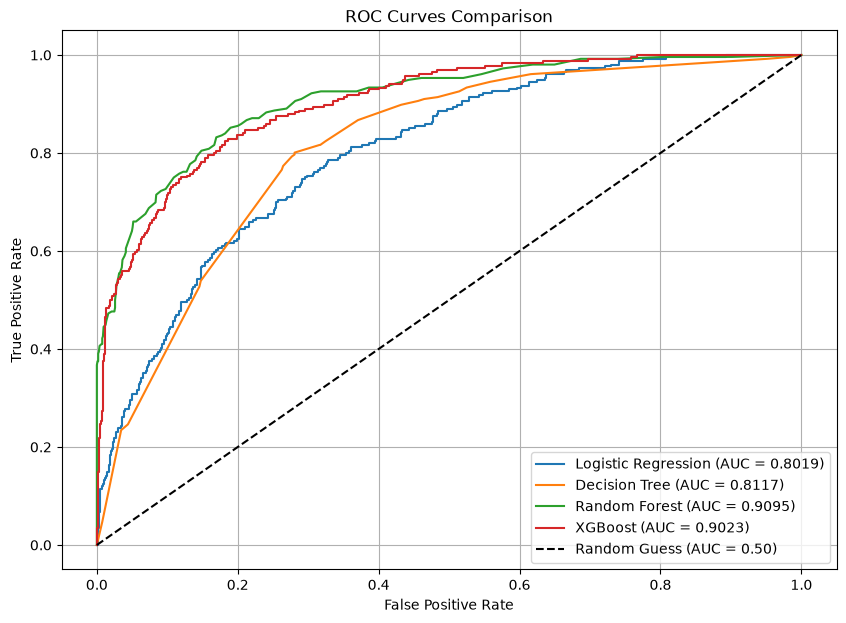

=== FINAL MODEL COMPARISON ===
              Model  Precision (High Quality)  Recall (High Quality)  F1-Score  ROC-AUC  False Positives  False Negatives
      Random Forest                  0.706122               0.675781  0.690619 0.909513               72               83
            XGBoost                  0.643382               0.683594  0.662879 0.902333               97               81
      Decision Tree                  0.411647               0.800781  0.543767 0.811718              293               51
Logistic Regression                  0.382470               0.750000  0.506596 0.801904              310               64


In [4]:
results = []                                                                 
plt.figure(figsize=(10, 7))                                                  
                                                                             
                                                                             
for name, config in models.items():                                          
    model = config["model"]                                                  
                                                                             
    # Select appropriate dataset (scaled vs unscaled)                        
    X_tr = X_train_scaled if config["scaled"] else X_train                   
    X_te = X_test_scaled if config["scaled"] else X_test                     
                                                                             
    # Train                                                                  
    model.fit(X_tr, y_train)                                                 
                                                                             
    # Predict                                                                
    y_pred = model.predict(X_te)                                             
    y_proba = model.predict_proba(X_te)[:, 1]                                
                                                                             
    # Metrics                                                                
    precision = precision_score(y_test, y_pred)                              
    recall = recall_score(y_test, y_pred)                                    
    f1 = f1_score(y_test, y_pred)                                            
    roc_auc = roc_auc_score(y_test, y_proba)                                 
    cm = confusion_matrix(y_test, y_pred)                                    
                                                                             
    results.append({                                                         
        "Model": name,                                                       
        "Precision (High Quality)": precision,                               
        "Recall (High Quality)": recall,                                     
        "F1-Score": f1,                                                      
        "ROC-AUC": roc_auc,                                                  
        "False Positives": cm[0, 1],                                         
        "False Negatives": cm[1, 0]                                          
    })                                                                       
                                                                             
    # Plot ROC Curve                                                         
    fpr, tpr, _ = roc_curve(y_test, y_proba)                                 
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")                
                                                                             
                                                                             
# Finalize ROC Curve Plot                                                    
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.50)")           
plt.xlabel("False Positive Rate")                                            
plt.ylabel("True Positive Rate")                                             
plt.title("ROC Curves Comparison")                                           
plt.legend(loc="lower right")                                                
plt.grid(True)                                                               
plt.show()                                                                   
                                                                             
                                                                             
# Display Comparison Table                                                   
df_results = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("=== FINAL MODEL COMPARISON ===")                                      
print(df_results.to_string(index=False))                                     

# 5. Plot Confusion Matrices Side by Side

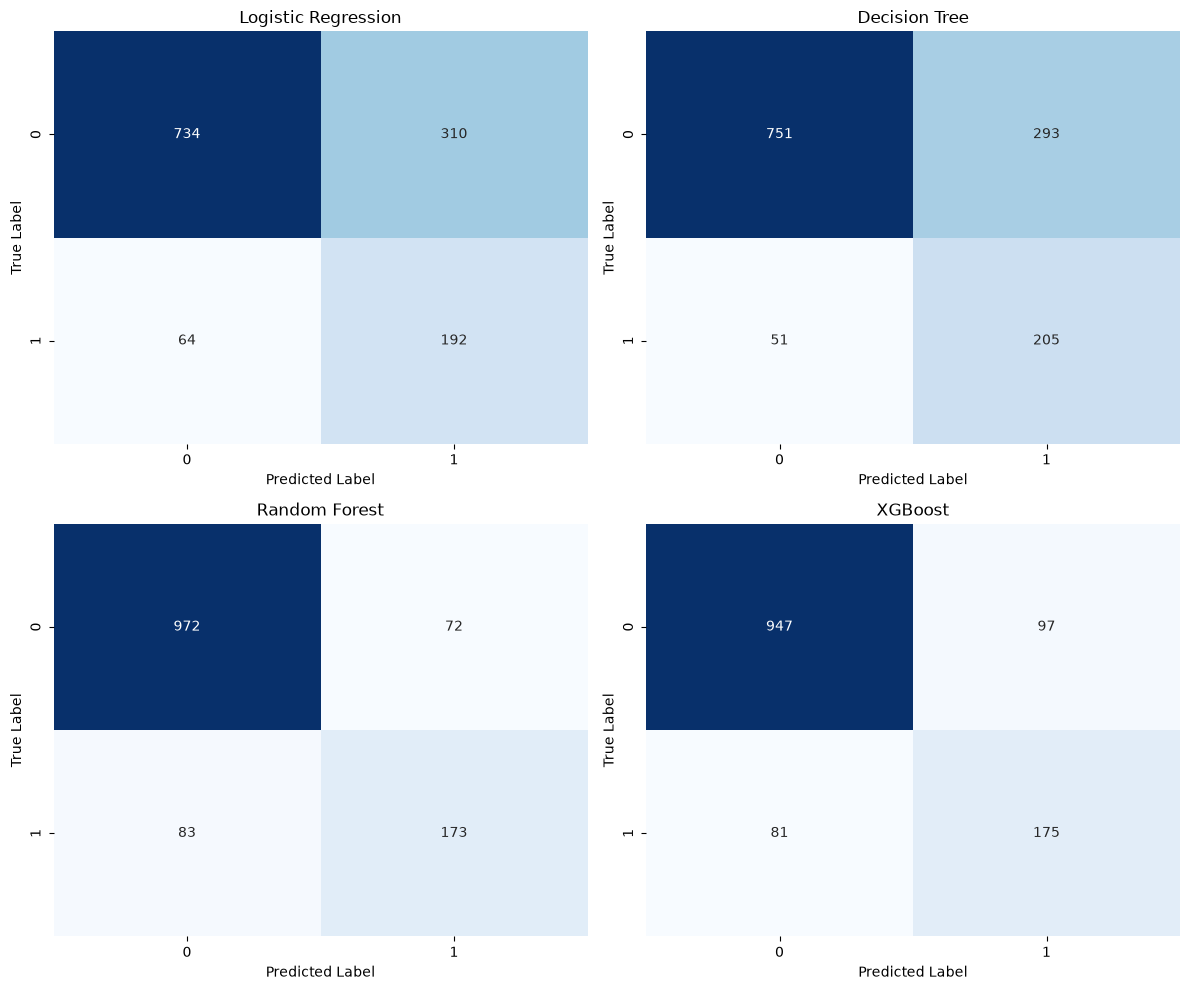

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))                                
axes = axes.flatten()                                                           
                                                                                
                                                                                
for idx, (name, config) in enumerate(models.items()):                           
    model = config["model"]                                                     
    X_te = X_test_scaled if config["scaled"] else X_test                        
    y_pred = model.predict(X_te)                                                
    cm = confusion_matrix(y_test, y_pred)                                       
                                                                                
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}")                                              
    axes[idx].set_xlabel("Predicted Label")                                     
    axes[idx].set_ylabel("True Label")                                          
                                                                                
                                                                                
plt.tight_layout()                                                              
plt.show()                                                                      